In [1]:
import pandas as pd, numpy as np, time
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from scipy import stats
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import warnings; warnings.filterwarnings("ignore")

PROC = Path("../data/processed")
FIG  = Path("../results/figures"); TAB = Path("../results/tables")
SUB_ORDER = ["LumA", "LumB", "Her2", "Basal", "Normal"]
sns.set_theme(style="whitegrid", font_scale=1.05)
SEED = 42

meta   = pd.read_csv(PROC / "meta_clean.csv")
logcpm = pd.read_csv(PROC / "logcpm.csv", index_col="gene")
X = logcpm.T.values                         # samples x genes (1083 x 15959)
gene_names = logcpm.index.to_numpy()
le = LabelEncoder().fit(SUB_ORDER)
y = le.transform(meta["subtype"])           # integer labels (XGBoost needs these)
CLASSES = le.classes_

# 20% hold-out test set, stratified; not touched until the final evaluation
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_tr.shape[0], "| Test:", X_te.shape[0])

Train: 866 | Test: 217


In [3]:
K_BEST = 500
def make_pipe(clf, k=K_BEST):
    return Pipeline([("select", SelectKBest(f_classif, k=k)),   # ANOVA F-test, fitted on training folds only
                     ("scale", StandardScaler()),
                     ("clf", clf)])

MODELS = {
    "Logistic Regression": LogisticRegression(C=0.1, max_iter=5000, class_weight="balanced"),
    "SVM (linear)":        SVC(kernel="linear", C=0.01, class_weight="balanced"),
    "Random Forest":       RandomForestClassifier(n_estimators=500, class_weight="balanced", n_jobs=-1, random_state=SEED),
    "XGBoost":             XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1, subsample=0.8,
                                         colsample_bytree=0.5, eval_metric="mlogloss", n_jobs=-1, random_state=SEED),
    "LightGBM":            LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, class_weight="balanced",
                                          subsample=0.8, subsample_freq=1, colsample_bytree=0.5, verbose=-1, random_state=SEED),
}

def fit_pipe(pipe, Xa, ya):
    if isinstance(pipe.named_steps["clf"], XGBClassifier):      # XGBoost: balance classes with sample weights
        pipe.fit(Xa, ya, clf__sample_weight=compute_sample_weight("balanced", ya))
    else:
        pipe.fit(Xa, ya)
    return pipe

def scores(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "macro_F1": f1_score(y_true, y_pred, average="macro")}

Logistic Regression  done in 1s
SVM (linear)         done in 1s
Random Forest        done in 5s
XGBoost              done in 23s
LightGBM             done in 11s
                    accuracy        balanced_accuracy        macro_F1       
                        mean    std              mean    std     mean    std
model                                                                       
Logistic Regression    0.898  0.029             0.859  0.035    0.848  0.054
SVM (linear)           0.894  0.020             0.848  0.039    0.842  0.049
XGBoost                0.911  0.017             0.825  0.019    0.840  0.026
LightGBM               0.906  0.011             0.806  0.016    0.831  0.030
Random Forest          0.885  0.028             0.818  0.014    0.831  0.022


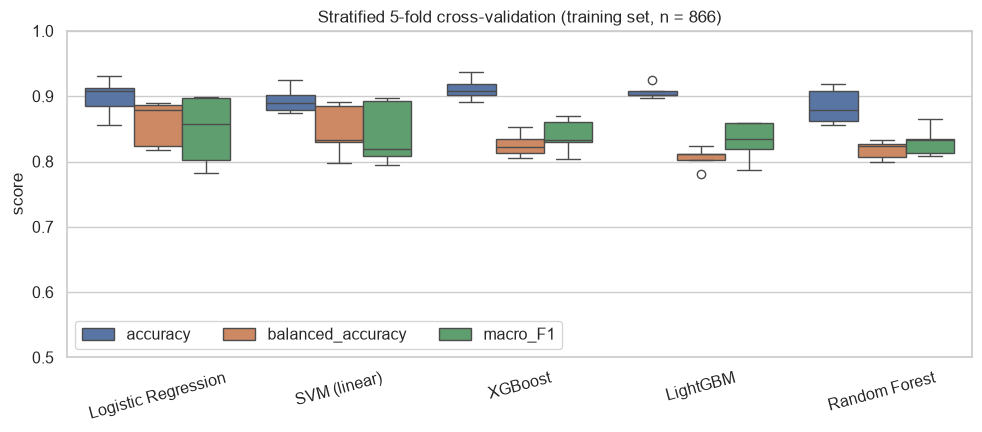

In [4]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for name, clf in MODELS.items():
    t = time.time()
    for fold, (i_tr, i_va) in enumerate(skf.split(X_tr, y_tr)):
        pipe = fit_pipe(make_pipe(clf), X_tr[i_tr], y_tr[i_tr])
        cv_rows.append({"model": name, "fold": fold, **scores(y_tr[i_va], pipe.predict(X_tr[i_va]))})
    print(f"{name:20s} done in {time.time() - t:.0f}s")
cv = pd.DataFrame(cv_rows)
cv_summary = (cv.groupby("model")[["accuracy", "balanced_accuracy", "macro_F1"]].agg(["mean", "std"]).round(3)
                .sort_values(("macro_F1", "mean"), ascending=False))
cv_summary.to_csv(TAB / "08_cv_results.csv")
print(cv_summary)

fig, ax = plt.subplots(figsize=(10, 4.5))
cvl = cv.melt(id_vars=["model", "fold"], var_name="metric", value_name="score")
sns.boxplot(data=cvl, x="model", y="score", hue="metric", ax=ax, order=cv_summary.index)
ax.set(title=f"Stratified 5-fold cross-validation (training set, n = {len(y_tr)})", xlabel="", ylim=(0.5, 1))
ax.legend(loc="lower left", ncol=3); ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.savefig(FIG / "08_cv_model_comparison.png", dpi=200); plt.show()

   k  macro_F1_mean  macro_F1_sd
  10          0.716        0.029
  25          0.758        0.020
  50          0.805        0.029
 100          0.849        0.040
 200          0.838        0.041
 500          0.848        0.048
1000          0.854        0.043
2000          0.849        0.053


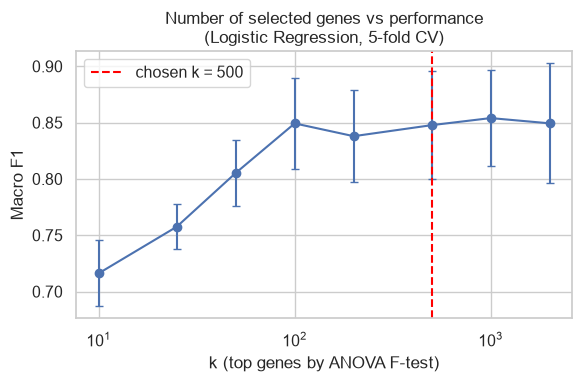

In [5]:
k_rows = []
for k in [10, 25, 50, 100, 200, 500, 1000, 2000]:
    f1s = [f1_score(y_tr[i_va], fit_pipe(make_pipe(MODELS["Logistic Regression"], k), X_tr[i_tr], y_tr[i_tr])
                    .predict(X_tr[i_va]), average="macro") for i_tr, i_va in skf.split(X_tr, y_tr)]
    k_rows.append({"k": k, "macro_F1_mean": np.mean(f1s), "macro_F1_sd": np.std(f1s)})
k_res = pd.DataFrame(k_rows); k_res.to_csv(TAB / "08_k_sensitivity.csv", index=False)
print(k_res.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(k_res["k"], k_res["macro_F1_mean"], yerr=k_res["macro_F1_sd"], fmt="o-", capsize=3)
ax.axvline(K_BEST, color="red", ls="--", label=f"chosen k = {K_BEST}")
ax.set(xscale="log", title="Number of selected genes vs performance\n(Logistic Regression, 5-fold CV)",
       xlabel="k (top genes by ANOVA F-test)", ylabel="Macro F1"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "08_k_sensitivity.png", dpi=200); plt.show()

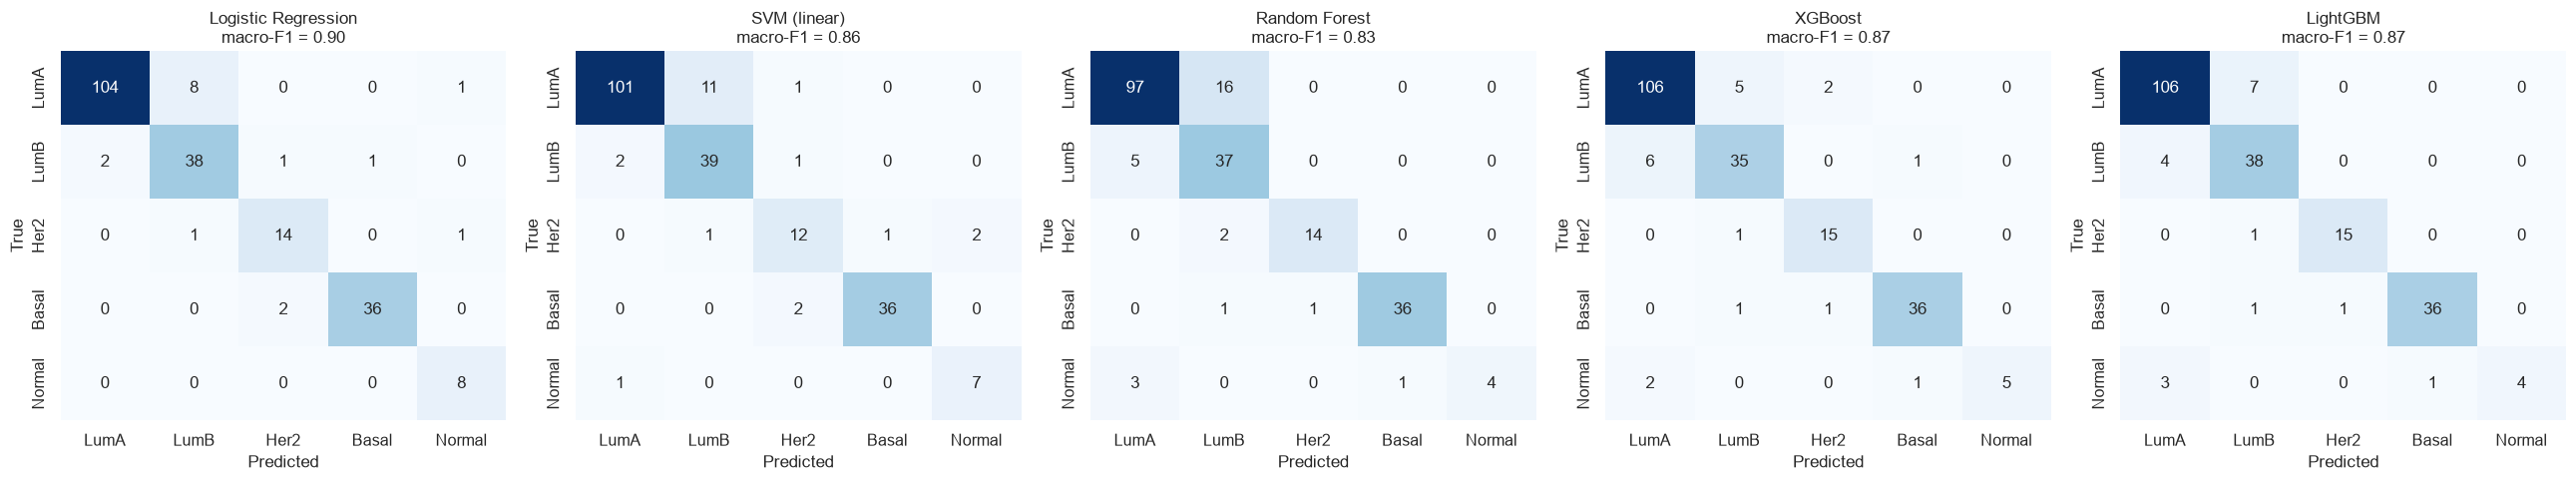

Held-out test set (n = 217):
                      accuracy  balanced_accuracy  macro_F1
model                                                     
Logistic Regression     0.922              0.929     0.900
XGBoost                 0.908              0.856     0.873
LightGBM                0.917              0.846     0.871
SVM (linear)            0.899              0.879     0.861
Random Forest           0.866              0.812     0.835

Per-class report for the best model (Logistic Regression):
               precision  recall  f1-score  support
LumA              0.981   0.920     0.950  113.000
LumB              0.809   0.905     0.854   42.000
Her2              0.824   0.875     0.848   16.000
Basal             0.973   0.947     0.960   38.000
Normal            0.800   1.000     0.889    8.000
accuracy          0.922   0.922     0.922    0.922
macro avg         0.877   0.929     0.900  217.000
weighted avg      0.928   0.922     0.923  217.000


In [6]:
test_rows, fitted = [], {}
fig, axes = plt.subplots(1, 5, figsize=(26, 5))
for ax, (name, clf) in zip(axes, MODELS.items()):
    pipe = fit_pipe(make_pipe(clf), X_tr, y_tr)
    fitted[name] = pipe
    pred = pipe.predict(X_te)
    test_rows.append({"model": name, **scores(y_te, pred)})
    cm = confusion_matrix(y_te, pred, labels=le.transform(SUB_ORDER))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=SUB_ORDER, yticklabels=SUB_ORDER)
    ax.set(title=f"{name}\nmacro-F1 = {test_rows[-1]['macro_F1']:.2f}", xlabel="Predicted", ylabel="True")
plt.tight_layout(); plt.savefig(FIG / "08_confusion_matrices.png", dpi=200); plt.show()

test = pd.DataFrame(test_rows).set_index("model").round(3).sort_values("macro_F1", ascending=False)
test.to_csv(TAB / "08_test_results.csv")
print(f"Held-out test set (n = {len(y_te)}):\n", test)

best = test.index[0]
rep = pd.DataFrame(classification_report(y_te, fitted[best].predict(X_te), labels=le.transform(SUB_ORDER),
                                         target_names=SUB_ORDER, output_dict=True)).T.round(3)
rep.to_csv(TAB / "08_best_model_classification_report.csv")
print(f"\nPer-class report for the best model ({best}):\n", rep)

PAM50 genes in our data: 49/50 | in our top 500: 33 (expected by chance 1.5, hypergeometric p = 1.7e-38)
Overlap: ['ANLN', 'BCL2', 'BIRC5', 'CCNB1', 'CCNE1', 'CDC20', 'CDH3', 'CENPF', 'CEP55', 'CXXC5', 'ESR1', 'EXO1', 'FOXA1', 'FOXC1', 'GPR160', 'KIF2C', 'MAPT', 'MELK', 'MKI67', 'MLPH', 'MYBL2', 'NAT1', 'NDC80', 'NUF2', 'ORC6', 'PGR', 'PHGDH', 'PTTG1', 'RRM2', 'SFRP1', 'SLC39A6', 'UBE2C', 'UBE2T']


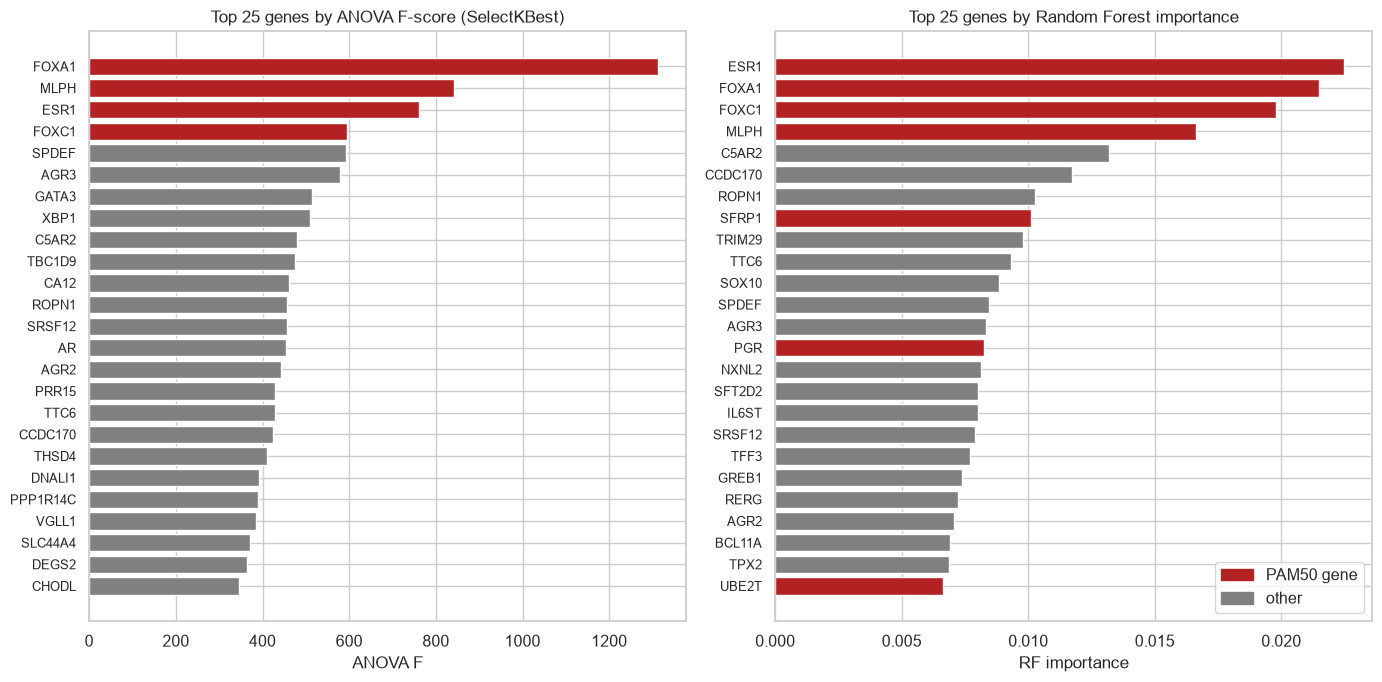

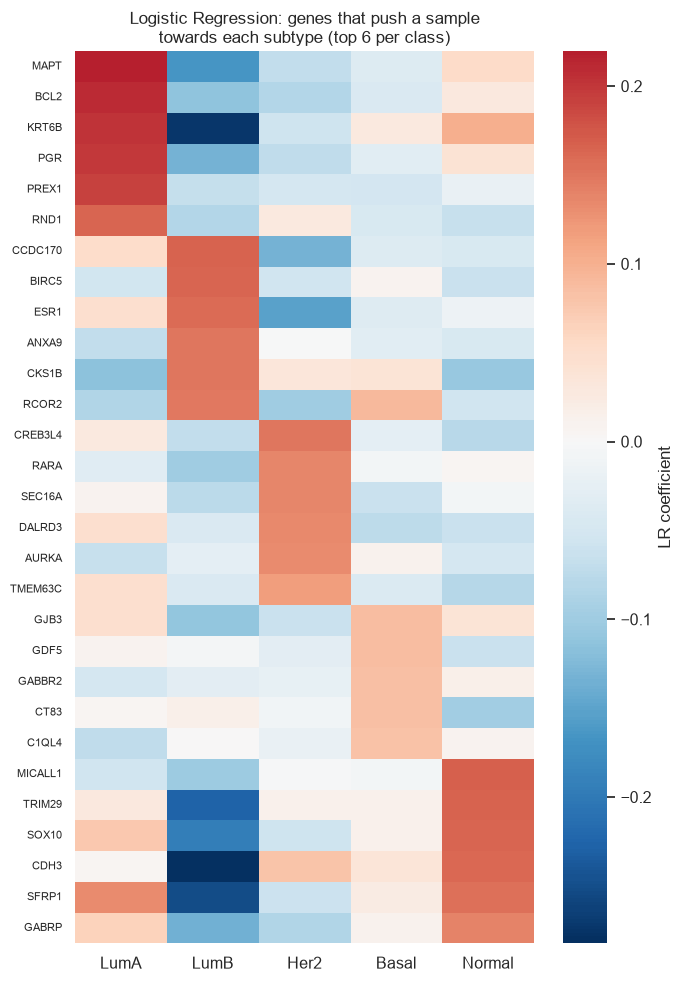

           ANOVA_F  RF_importance  in_PAM50
ESR1      759.8865         0.0225      True
FOXA1    1311.8745         0.0215      True
FOXC1     594.1387         0.0198      True
MLPH      841.0601         0.0166      True
C5AR2     480.4372         0.0132     False
CCDC170   425.1342         0.0117     False
ROPN1     457.3583         0.0103     False
SFRP1     183.3073         0.0101      True
TRIM29    148.5399         0.0098     False
TTC6      428.5685         0.0093     False
SOX10     168.8441         0.0088     False
SPDEF     591.7251         0.0084     False
AGR3      578.3308         0.0083     False
PGR       202.1252         0.0082      True
NXNL2     150.0559         0.0081     False


In [7]:
sel = fitted["Logistic Regression"].named_steps["select"]
selected = gene_names[sel.get_support()]
fscore  = pd.Series(sel.scores_, index=gene_names).loc[selected]
rf_imp  = pd.Series(fitted["Random Forest"].named_steps["clf"].feature_importances_, index=selected)
lr_coef = pd.DataFrame(fitted["Logistic Regression"].named_steps["clf"].coef_, index=CLASSES, columns=selected)

PAM50 = ("ACTR3B ANLN BAG1 BCL2 BIRC5 BLVRA CCNB1 CCNE1 CDC20 CDC6 CDH3 CENPF CEP55 CXXC5 EGFR ERBB2 ESR1 EXO1 "
         "FGFR4 FOXA1 FOXC1 GPR160 GRB7 KIF2C KRT14 KRT17 KRT5 MAPT MDM2 MELK MIA MKI67 MLPH MMP11 MYBL2 MYC NAT1 "
         "NDC80 NUF2 ORC6 PGR PHGDH PTTG1 RRM2 SFRP1 SLC39A6 TMEM45B TYMS UBE2C UBE2T").split()
pam50_here = [g for g in PAM50 if g in set(gene_names)]
overlap = sorted(set(selected) & set(pam50_here))
p_hyper = stats.hypergeom.sf(len(overlap) - 1, len(gene_names), len(pam50_here), len(selected))
print(f"PAM50 genes in our data: {len(pam50_here)}/50 | in our top {len(selected)}: {len(overlap)} "
      f"(expected by chance {len(selected) * len(pam50_here) / len(gene_names):.1f}, hypergeometric p = {p_hyper:.1e})")
print("Overlap:", overlap)

imp = pd.DataFrame({"ANOVA_F": fscore, "RF_importance": rf_imp}).sort_values("RF_importance", ascending=False)
imp["in_PAM50"] = imp.index.isin(PAM50)
imp.to_csv(TAB / "08_feature_importance.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, (col, title) in zip(axes, [("ANOVA_F", "Top 25 genes by ANOVA F-score (SelectKBest)"),
                                   ("RF_importance", "Top 25 genes by Random Forest importance")]):
    t = imp[col].nlargest(25)[::-1]
    ax.barh(t.index, t.values, color=["firebrick" if g in PAM50 else "grey" for g in t.index])
    ax.set(title=title, xlabel=col.replace("_", " ")); ax.tick_params(axis="y", labelsize=9)
axes[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color="firebrick"), plt.Rectangle((0, 0), 1, 1, color="grey")],
               labels=["PAM50 gene", "other"], loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "08_feature_importance.png", dpi=200); plt.show()

top_genes = list(dict.fromkeys(g for c in SUB_ORDER for g in lr_coef.loc[c].nlargest(6).index))
fig, ax = plt.subplots(figsize=(7, 10))
sns.heatmap(lr_coef.loc[SUB_ORDER, top_genes].T, cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "LR coefficient"})
ax.set(title="Logistic Regression: genes that push a sample\ntowards each subtype (top 6 per class)", xlabel="", ylabel="")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.savefig(FIG / "08_lr_coefficients.png", dpi=200); plt.show()
print(imp.head(15).round(4))